# 🧪 Notebook 7 — Dynamic Monte Carlo: ATRP & Polymer Degradation
| | |
|---|---|
| ⏱ Time | ~40 min |
| 🧭 Type | **dynamic Monte Carlo** (book Ch. 4) |
| 🎯 You will learn | reuse Gillespie's method for (A) **controlled** radical polymerization and (B) **breaking** polymers apart |
| 🧰 Uses | everything from Notebook 6 |
| 📖 Book | Case Study 4.3 (ATRP copolymerization) · Case Study 4.4 (thermal degradation of polystyrene) |

Both mechanisms here are **simplified** (homopolymer ATRP; two-reaction degradation) with illustrative parameters, so the ideas stay clear and each run takes a few seconds. The full mechanisms are in *Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture*.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson

random.seed(9)

Two tools from Notebook 6, reused unchanged:

In [2]:
def take_random(pool):
    k = random.randrange(len(pool))
    chosen = pool[k]
    pool[k] = pool[-1]
    pool.pop()
    return chosen

In [3]:
def pick_event(rates):
    r = random.random() * sum(rates)
    cumulative = 0
    for j in range(len(rates)):
        cumulative += rates[j]
        if r <= cumulative:
            return j

## Part A · ATRP: chains that *sleep* most of the time 😴
In ATRP all chains start together and spend most of their life **dormant** (`P–X`). A copper catalyst wakes one up briefly:

| reaction | what happens |
|---|---|
| activation | `P–X + Cu(I) → P• + Cu(II)X` |
| deactivation | `P• + Cu(II)X → P–X + Cu(I)` |
| propagation | `P•ₙ + M → P•ₙ₊₁` |
| combination | `P• + P• → dead` |

Because every chain grows a little, sleeps, then grows again, they end up **almost the same length**: low Đ, and `Nn` grows **linearly** with conversion.

### A.1 · Parameters and the state
200 dormant chains and 20,000 monomer molecules (target chain length 100). The microscopic constants follow Table 4.1 (`V·N_A = 10⁴ L/mol`).

In [4]:
VNA = 1e4
ka_MC  = 111.0 / VNA        # activation
kda_MC = 1e5 / VNA          # deactivation
kp_MC  = 100.0 / VNA        # propagation
ktc_MC = 2 * 6e2 / VNA      # combination
nM0 = 20_000

In [5]:
def new_atrp():
    return {"dormant": [0] * 200,     # 200 sleeping chains, length 0
            "active": [], "dead": [],
            "nCu1": 180, "nCu2": 20, "nM": nM0}

### A.2 · One function per reaction

In [6]:
def activation(s):
    s["active"].append(take_random(s["dormant"]))
    s["nCu1"] -= 1
    s["nCu2"] += 1

In [7]:
def deactivation(s):
    s["dormant"].append(take_random(s["active"]))
    s["nCu1"] += 1
    s["nCu2"] -= 1

In [8]:
def propagation(s):
    k = random.randrange(len(s["active"]))
    s["active"][k] += 1
    s["nM"] -= 1

In [9]:
def combination(s):
    n = take_random(s["active"])
    m = take_random(s["active"])
    s["dead"].append(n + m)

In [10]:
ATRP_REACTIONS = [activation, deactivation, propagation, combination]

def atrp_propensities(s):
    nP = len(s["active"])
    return [ka_MC * len(s["dormant"]) * s["nCu1"],
            kda_MC * nP * s["nCu2"],
            kp_MC * nP * s["nM"],
            ktc_MC * nP * (nP - 1) / 4]

### A.3 · Run to 90 % conversion
Every 500 events, record the conversion, `Nn`, `Đ` and the amount of Cu(II). A helper computes Nn and Đ over all chains (dormant + active + dead):

In [11]:
def averages(s):
    chains = np.array(s["dormant"] + s["active"] + s["dead"])
    Nn = chains.mean()
    Nw = np.sum(chains**2) / np.sum(chains)
    return Nn, Nw / Nn

In [12]:
s = new_atrp()
step = 0
hist = {"x": [], "Nn": [], "PDI": [], "Cu2": []}

while (nM0 - s["nM"]) / nM0 < 0.9:
    j = pick_event(atrp_propensities(s))
    ATRP_REACTIONS[j](s)
    step += 1
    if step % 500 == 0:
        Nn, PDI = averages(s)
        hist["x"].append((nM0 - s["nM"]) / nM0)
        hist["Nn"].append(Nn); hist["PDI"].append(PDI); hist["Cu2"].append(s["nCu2"])

(We don't need the clock here, only the order of events, so the time update is left out.)

In [13]:
print(f"{step:,} events.   Final Đ = {hist['PDI'][-1]:.3f}   (free-radical polymerization: ~1.5–2)")

165,469 events.   Final Đ = 1.038   (free-radical polymerization: ~1.5–2)


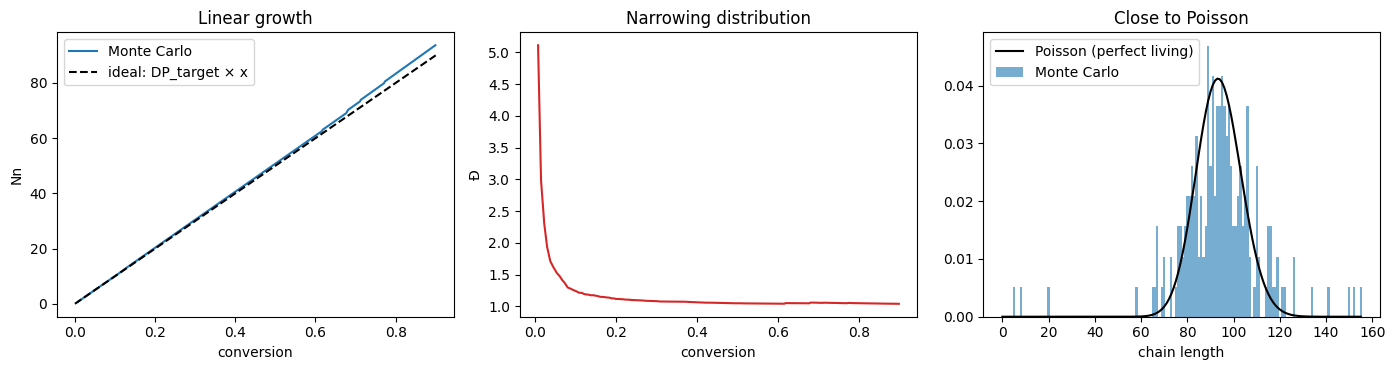

In [14]:
#@title Plot Nn, Đ and the chain length distribution
chains = np.array(s["dormant"] + s["active"] + s["dead"])
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].plot(hist["x"], hist["Nn"], label="Monte Carlo"); ax[0].plot([0, 0.9], [0, 90], "k--", label="ideal: DP_target × x")
ax[0].set_xlabel("conversion"); ax[0].set_ylabel("Nn"); ax[0].legend(); ax[0].set_title("Linear growth")
ax[1].plot(hist["x"], hist["PDI"], c="tab:red"); ax[1].set_xlabel("conversion"); ax[1].set_ylabel("Đ"); ax[1].set_title("Narrowing distribution")
nn = np.arange(0, chains.max()+1)
ax[2].bar(nn, np.bincount(chains, minlength=len(nn))/len(chains), width=1, alpha=0.6, label="Monte Carlo")
ax[2].plot(nn, poisson.pmf(nn, chains.mean()), "k-", label="Poisson (perfect living)")
ax[2].set_xlabel("chain length"); ax[2].legend(); ax[2].set_title("Close to Poisson")
plt.tight_layout(); plt.show()

📝 If `Nn` rises a little above the ideal line, that's combination: every coupling turns two chains into one.

💡 **Persistent radical effect:** every combination leaves an extra Cu(II)X behind, which then *slows down* further termination. Self-regulating chemistry:

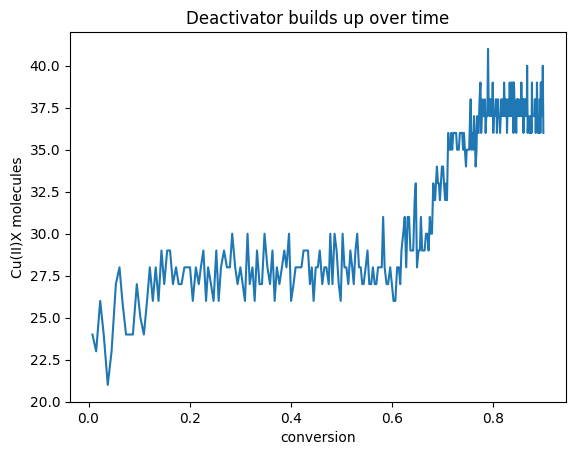

In [15]:
#@title Plot the Cu(II) build-up
plt.plot(hist["x"], hist["Cu2"]); plt.xlabel("conversion"); plt.ylabel("Cu(II)X molecules")
plt.title("Deactivator builds up over time"); plt.show()

## Part B · Degradation: polymerization in reverse 🔥
Start from a Flory distribution (like Notebook 2) and break the chains with two simplified reactions:

| reaction | propensity | effect |
|---|---|---|
| random scission | `k_s × (number of C–C bonds)` | a chain of length n splits at a random bond |
| end unzipping | `k_dp × (number of chain ends)` | one monomer drops off a chain end |

### B.1 · The starting polymer
1000 chains with an average length of 100 (only chains with at least 2 units).

In [16]:
start = np.random.default_rng(0).geometric(1/100, size=1000)
chains0 = []
for L in start:
    if L >= 2:
        chains0.append(int(L))

total_units = sum(chains0)
print(len(chains0), "chains,", total_units, "monomer units")

986 chains, 102174 monomer units


### B.2 · Picking a random bond
A chain of length `n` has `n − 1` bonds, so long chains should be picked more often. A neat trick, **rejection sampling**: pick a random chain, and *accept* it with probability `(n − 1)/(n_max − 1)`; otherwise try again.

In [17]:
def pick_chain_by_bonds(chains, n_max):
    while True:
        k = random.randrange(len(chains))
        if random.random() <= (chains[k] - 1) / (n_max - 1):
            return k

### B.3 · The two reactions
A piece of length 1 is a free monomer (it evaporates), so it leaves the list and is counted in `monomer`.

In [18]:
def remove_if_monomer(s, k):
    if s["chains"][k] == 1:
        s["chains"][k] = s["chains"][-1]
        s["chains"].pop()
        s["monomer"] += 1

In [19]:
def scission(s):
    k = pick_chain_by_bonds(s["chains"], s["n_max"])
    cut = random.randint(1, s["chains"][k] - 1)        # which bond
    s["chains"].append(s["chains"][k] - cut)            # right-hand piece
    s["chains"][k] = cut                                # left-hand piece
    s["bonds"] -= 1
    remove_if_monomer(s, len(s["chains"]) - 1)
    remove_if_monomer(s, k)

In [20]:
def unzip(s):
    k = random.randrange(len(s["chains"]))
    s["chains"][k] -= 1
    s["monomer"] += 1
    s["bonds"] -= 1
    remove_if_monomer(s, k)

### B.4 · The Gillespie loop

In [21]:
def new_polymer():
    return {"chains": list(chains0), "monomer": 0, "n_max": max(chains0),
            "bonds": total_units - len(chains0)}

After each event we record the time, the number-average chain length (counting free monomer too) and the monomer yield:

In [22]:
def record(history, t, s):
    history["t"].append(t)
    history["DPn"].append(total_units / (len(s["chains"]) + s["monomer"]))
    history["yield"].append(s["monomer"] / total_units)

In [23]:
def degrade(ks, kdp, t_end=100.0):
    s = new_polymer()
    t = 0.0
    history = {"t": [], "DPn": [], "yield": []}
    while t < t_end:
        R = [ks * s["bonds"], kdp * 2 * len(s["chains"])]
        if pick_event(R) == 0:
            scission(s)
        else:
            unzip(s)
        t += np.log(1 / random.random()) / sum(R)
        record(history, t, s)
    return history

### B.5 · ✅ Check random scission against theory
For random scission alone, `1/DPn = 1 − (1 − 1/DPn₀)·e^(−k_s t)` (≈ `1/DPn₀ + k_s t` at early times).

In [24]:
h = degrade(ks=1e-3, kdp=0.0)
t_s = np.array(h["t"])
DPn0 = total_units / len(chains0)
theory = 1 - (1 - 1/DPn0) * np.exp(-1e-3 * t_s)
print(f"at t = 100 s:  Monte Carlo 1/DPn = {1/h['DPn'][-1]:.4f}   theory = {theory[-1]:.4f}")

at t = 100 s:  Monte Carlo 1/DPn = 0.1051   theory = 0.1039


### B.6 · Unzipping recovers monomer

In [25]:
unzip_runs = {}
for kdp in [0.0, 0.02, 0.1]:
    unzip_runs[kdp] = degrade(ks=1e-3, kdp=kdp)

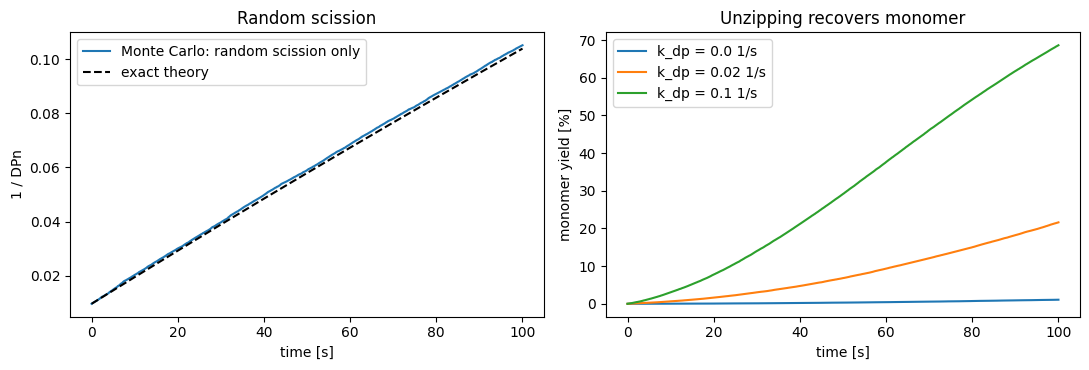

In [26]:
#@title Plot 1/DPn and the monomer yield
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(t_s, 1/np.array(h["DPn"]), label="Monte Carlo: random scission only"); ax[0].plot(t_s, theory, "k--", label="exact theory")
ax[0].set_xlabel("time [s]"); ax[0].set_ylabel("1 / DPn"); ax[0].legend(); ax[0].set_title("Random scission")
for kdp, hk in unzip_runs.items():
    ax[1].plot(hk["t"], 100*np.array(hk["yield"]), label=f"k_dp = {kdp} 1/s")
ax[1].set_xlabel("time [s]"); ax[1].set_ylabel("monomer yield [%]"); ax[1].legend(); ax[1].set_title("Unzipping recovers monomer")
plt.tight_layout(); plt.show()

## 🎓 Course recap so far
| Notebook | Core idea | Data structure |
|---|---|---|
| 1 | `Rnd ≤ P`, counting, roulette wheel, waiting times | – |
| 2 | one chain at a time → MWD | counting vector `D` |
| 3 | an extra label per chain (composition) | lists `D`, `N1` |
| 4 | molecules that react again | pool list |
| 5 | pick two and merge; networks | pools, parents |
| 6–7 | dynamic Monte Carlo: real time from rates | lists of active / dormant / dead chains |

### 🧪 Try it yourself
1. ATRP: lower the deactivation constant 10×. What happens to Đ? Why?
2. ATRP: start with `nCu2 = 0`. Look at the first few hundred events.
3. Degradation: start from a narrow (Poisson) distribution instead of Flory. Does random scission push it toward Đ = 2?

➡️ **Next: Notebooks 8–10 — case studies from the book, with the book's parameters**